In [35]:
import shutil
from pathlib import Path

for folder in ["results", "data"]:
    p = Path("/content/DS-A3-Regression-Baseline") / folder
    if p.exists():
        shutil.rmtree(p)
        print("deleted", p)
    else:
        print("not present", p)

deleted /content/DS-A3-Regression-Baseline/results
deleted /content/DS-A3-Regression-Baseline/data


# DS-A3 Regression Baseline
## Evaluation rules
- Use chronological train/validation/test partitions.
- Use validation data for model comparison; keep the test partition untouched until the feature/model decisions are frozen.
- Treat `Ridge` without `yr` as the primary feature-plan baseline. Treat `Ridge_with_year` as a sensitivity-analysis candidate, not as proof of reliable forecasting.
- Interpret negative validation R² as a serious performance limitation.
- Same-day weather variables are appropriate only if the intended prediction is made when those measurements are available; for a forecast made before the day begins, use forecast weather or exclude realized same-day weather.
- Cook’s distance is a screening diagnostic, not a rule for automatically deleting observations.


In [36]:

from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile
from io import BytesIO
import hashlib
import json
import platform
import sys

import numpy as np
import pandas as pd
import sklearn

# DS-A3: data acquisition and provenance audit
SEED = 20261021

DATA_URL = (
    "https://archive.ics.uci.edu/static/"
    "public/275/bike+sharing+dataset.zip"
)

PROJECT = Path("/content/DS-A3-Regression-Baseline")
DATA_DIR = PROJECT / "data"
RESULTS_DIR = PROJECT / "results"

DATA_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Download the source archive
with urlopen(DATA_URL, timeout=60) as response:
    archive_bytes = response.read()

archive_sha256 = hashlib.sha256(archive_bytes).hexdigest()

# Extract only the required daily dataset
with ZipFile(BytesIO(archive_bytes)) as archive:
    members = archive.namelist()
    day_files = [
        name for name in members
        if name.endswith("day.csv")
    ]
    if len(day_files) != 1:
        raise ValueError(
            f"Expected one day.csv file; found {day_files}"
        )
    day_bytes = archive.read(day_files[0])

day_sha256 = hashlib.sha256(day_bytes).hexdigest()
EXPECTED_DAY_SHA256 = (
    "a6bcf826782d3c0fbfdcbeead17cd0884185a0dafe8ff10cd48a874ee7ba18be"
)
if day_sha256 != EXPECTED_DAY_SHA256:
    raise ValueError(
        "day.csv SHA-256 does not match the expected dataset. "
        f"Expected {EXPECTED_DAY_SHA256}; got {day_sha256}. "
        "Do not continue until the dataset source/version is checked."
    )
day_path = DATA_DIR / "day.csv"
day_path.write_bytes(day_bytes)

df = pd.read_csv(day_path)
df["dteday"] = pd.to_datetime(df["dteday"])

# Verify essential schema and data integrity
required = {
    "dteday", "cnt", "casual", "registered",
    "season", "mnth", "weekday", "workingday",
    "holiday", "weathersit", "temp", "atemp",
    "hum", "windspeed"
}
missing_columns = sorted(required - set(df.columns))
if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

if df["cnt"].isna().any():
    raise ValueError("Target contains missing values.")

if df["dteday"].duplicated().any():
    raise ValueError("Duplicate dates detected.")

if not df["dteday"].is_monotonic_increasing:
    df = df.sort_values("dteday").reset_index(drop=True)

# Audit key target identity; do not use its components as features
target_identity_ok = bool(
    (df["casual"] + df["registered"] == df["cnt"]).all()
)
if not target_identity_ok:
    raise ValueError("Target component identity check failed.")

audit = {
    "source_url": DATA_URL,
    "archive_sha256": archive_sha256,
    "day_csv_sha256": day_sha256,
    "retrieved_day_csv_bytes": len(day_bytes),
    "rows": int(len(df)),
    "columns": list(df.columns),
    "date_min": str(df["dteday"].min().date()),
    "date_max": str(df["dteday"].max().date()),
    "missing_values": {
        k: int(v) for k, v in df.isna().sum().items()
    },
    "duplicate_rows": int(df.duplicated().sum()),
    "target_component_identity_verified": target_identity_ok,
    "python_version": sys.version,
    "platform": platform.platform(),
    "pandas_version": pd.__version__,
    "numpy_version": np.__version__,
    "scikit_learn_version": sklearn.__version__,
    "seed": SEED,
}

with open(RESULTS_DIR / "data_audit.json", "w") as f:
    json.dump(audit, f, indent=2)

print(json.dumps(audit, indent=2))


{
  "source_url": "https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip",
  "archive_sha256": "b70182d0d0508e9abbb79306ce5c0cec34869000f8220175ac83d11dbe845401",
  "day_csv_sha256": "a6bcf826782d3c0fbfdcbeead17cd0884185a0dafe8ff10cd48a874ee7ba18be",
  "retrieved_day_csv_bytes": 57569,
  "rows": 731,
  "columns": [
    "instant",
    "dteday",
    "season",
    "yr",
    "mnth",
    "holiday",
    "weekday",
    "workingday",
    "weathersit",
    "temp",
    "atemp",
    "hum",
    "windspeed",
    "casual",
    "registered",
    "cnt"
  ],
  "date_min": "2011-01-01",
  "date_max": "2012-12-31",
  "missing_values": {
    "instant": 0,
    "dteday": 0,
    "season": 0,
    "yr": 0,
    "mnth": 0,
    "holiday": 0,
    "weekday": 0,
    "workingday": 0,
    "weathersit": 0,
    "temp": 0,
    "atemp": 0,
    "hum": 0,
    "windspeed": 0,
    "casual": 0,
    "registered": 0,
    "cnt": 0
  },
  "duplicate_rows": 0,
  "target_component_identity_verified": true,
  "python

In [37]:

# DS-A3 Step 2: leakage audit and frozen chronological split

import json
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Reuse df, PROJECT, DATA_DIR, RESULTS_DIR from Step 1.
# Sort chronologically before defining split boundaries.
df = df.sort_values("dteday").reset_index(drop=True)

assert len(df) == 731, f"Unexpected row count: {len(df)}"
assert df["dteday"].is_monotonic_increasing
assert not df["dteday"].duplicated().any()
assert (df["casual"] + df["registered"] == df["cnt"]).all()

# Freeze boundaries by row count, without shuffling.
n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

split = np.full(n, "test", dtype=object)
split[:train_end] = "train"
split[train_end:val_end] = "validation"

df["split"] = split

train = df[df["split"] == "train"].copy()
val = df[df["split"] == "validation"].copy()
test = df[df["split"] == "test"].copy()

# Leakage audit: target components and identifiers are not predictors.
excluded_features = [
    "cnt", "casual", "registered", "instant", "dteday", "yr"
]

candidate_features = [
    col for col in df.columns
    if col not in excluded_features + ["split"]
]

# Explicitly record the planned feature set.
# Categorical variables will be encoded in a later pipeline.
feature_plan = {
    "numeric": ["temp", "atemp", "hum", "windspeed"],
    "categorical": [
        "season", "mnth", "holiday", "weekday",
        "workingday", "weathersit"
    ],
}

planned = feature_plan["numeric"] + feature_plan["categorical"]
assert set(planned).issubset(set(df.columns))
assert not set(planned).intersection(excluded_features)

# Naive baseline: always predict the training-set median.
baseline_value = float(train["cnt"].median())
val_pred = np.full(len(val), baseline_value)

baseline_validation = {
    "baseline": "training_median",
    "prediction_value": baseline_value,
    "validation_rows": int(len(val)),
    "validation_MAE": float(
        mean_absolute_error(val["cnt"], val_pred)
    ),
    "validation_RMSE": float(
        np.sqrt(mean_squared_error(val["cnt"], val_pred))
    ),
}

# Save exact row assignments and the split audit.
df[["dteday", "split"]].to_csv(
    RESULTS_DIR / "split_assignments.csv", index=False
)

split_audit = {
    "dataset_rows": n,
    "split_rule": "chronological; floor(0.70*n), floor(0.85*n)",
    "train": {
        "rows": len(train),
        "start": str(train["dteday"].min().date()),
        "end": str(train["dteday"].max().date()),
    },
    "validation": {
        "rows": len(val),
        "start": str(val["dteday"].min().date()),
        "end": str(val["dteday"].max().date()),
    },
    "test": {
        "rows": len(test),
        "start": str(test["dteday"].min().date()),
        "end": str(test["dteday"].max().date()),
    },
    "excluded_features": excluded_features,
    "planned_features": feature_plan,
    "baseline_validation": baseline_validation,
    "test_set_used_for_model_selection": False,
}

with open(RESULTS_DIR / "split_audit.json", "w") as f:
    json.dump(split_audit, f, indent=2)

print(json.dumps(split_audit, indent=2))


{
  "dataset_rows": 731,
  "split_rule": "chronological; floor(0.70*n), floor(0.85*n)",
  "train": {
    "rows": 511,
    "start": "2011-01-01",
    "end": "2012-05-25"
  },
  "validation": {
    "rows": 110,
    "start": "2012-05-26",
    "end": "2012-09-12"
  },
  "test": {
    "rows": 110,
    "start": "2012-09-13",
    "end": "2012-12-31"
  },
  "excluded_features": [
    "cnt",
    "casual",
    "registered",
    "instant",
    "dteday",
    "yr"
  ],
  "planned_features": {
    "numeric": [
      "temp",
      "atemp",
      "hum",
      "windspeed"
    ],
    "categorical": [
      "season",
      "mnth",
      "holiday",
      "weekday",
      "workingday",
      "weathersit"
    ]
  },
  "baseline_validation": {
    "baseline": "training_median",
    "prediction_value": 3974.0,
    "validation_rows": 110,
    "validation_MAE": 2781.2545454545457,
    "validation_RMSE": 2909.361060751687
  },
  "test_set_used_for_model_selection": false
}


In [38]:

# DS-A3 Step 3: regression candidates and validation comparison

import json
import warnings
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.exceptions import ConvergenceWarning

# Rebuild the chronological subsets from the audited dataframe.
df = df.sort_values("dteday").reset_index(drop=True)

n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

train = df.iloc[:train_end].copy()
val = df.iloc[train_end:val_end].copy()

numeric_features = ["temp", "atemp", "hum", "windspeed"]
categorical_features = [
    "season", "mnth", "holiday", "weekday",
    "workingday", "weathersit"
]
features = numeric_features + categorical_features
target = "cnt"

# Explicit leakage checks.
for forbidden in ["cnt", "casual", "registered",
                  "instant", "dteday", "yr", "split"]:
    assert forbidden not in features, f"Leakage risk: {forbidden}"

X_train = train[features]
y_train = train[target]
X_val = val[features]
y_val = val[target]

# Fit imputation, scaling and encoding inside each model pipeline.
numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipe, numeric_features),
    ("categorical", categorical_pipe, categorical_features)
])

# Keep folds in chronological order within the training period.
time_cv = TimeSeriesSplit(n_splits=5)

models = {
    "LinearRegression": Pipeline([
        ("preprocess", preprocessor),
        ("model", LinearRegression())
    ]),
    "Ridge": Pipeline([
        ("preprocess", preprocessor),
        ("model", Ridge())
    ]),
    "Lasso": Pipeline([
        ("preprocess", preprocessor),
        ("model", Lasso(max_iter=50000))
    ])
}

# Hyperparameter grids are specified before looking at validation results.
param_grids = {
    "LinearRegression": {},
    "Ridge": {"model__alpha": [0.01, 0.1, 1, 10, 100, 1000]},
    "Lasso": {"model__alpha": [0.001, 0.01, 0.1, 1, 10, 100]}
}

results = []
validation_predictions = {}
fitted_models = {}
tuning_details = {}

# Recompute the naive baseline using training data only.
baseline_value = float(y_train.median())
baseline_pred = np.full(len(y_val), baseline_value)

def calculate_metrics(y_true, y_pred):
    return {
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R2": float(r2_score(y_true, y_pred))
    }

results.append({
    "model": "TrainingMedianBaseline",
    "selected_alpha": None,
    **calculate_metrics(y_val, baseline_pred)
})
validation_predictions["TrainingMedianBaseline"] = baseline_pred

for name, pipeline in models.items():
    print(f"Fitting {name}...")

    if name == "LinearRegression":
        pipeline.fit(X_train, y_train)
        fitted = pipeline
        selected_alpha = None
        cv_best_mae = None
    else:
        search = GridSearchCV(
            estimator=pipeline,
            param_grid=param_grids[name],
            scoring="neg_mean_absolute_error",
            cv=time_cv,
            refit=True,
            n_jobs=-1,
            error_score="raise"
        )

        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always", ConvergenceWarning)
            search.fit(X_train, y_train)

        fitted = search.best_estimator_
        selected_alpha = float(search.best_params_["model__alpha"])
        cv_best_mae = float(-search.best_score_)

        convergence_warnings = [
            str(w.message) for w in caught
            if issubclass(w.category, ConvergenceWarning)
        ]
        if convergence_warnings:
            print(f"WARNING: {name} convergence issues:")
            for message in convergence_warnings:
                print(message)

    pred = fitted.predict(X_val)
    metrics = calculate_metrics(y_val, pred)

    fitted_models[name] = fitted
    validation_predictions[name] = pred
    tuning_details[name] = {
        "selected_alpha": selected_alpha,
        "best_training_cv_MAE": cv_best_mae,
        "candidate_alphas": param_grids[name].get(
            "model__alpha", []
        )
    }

    results.append({
        "model": name,
        "selected_alpha": selected_alpha,
        "training_cv_MAE": cv_best_mae,
        **metrics
    })

comparison = pd.DataFrame(results)
comparison.to_csv(
    RESULTS_DIR / "model_comparison_validation.csv",
    index=False
)

# Save row-level validation predictions for later error analysis.
prediction_table = pd.DataFrame({
    "dteday": val["dteday"].values,
    "actual_cnt": y_val.values,
})
for name, pred in validation_predictions.items():
    prediction_table[f"pred_{name}"] = pred

prediction_table.to_csv(
    RESULTS_DIR / "validation_predictions.csv",
    index=False
)

with open(RESULTS_DIR / "tuning_details.json", "w") as f:
    json.dump(tuning_details, f, indent=2)

print("\nVALIDATION COMPARISON")
print(comparison.round(4).to_string(index=False))
print("\nSaved validation comparison and predictions.")
print("The test set has not been evaluated.")


Fitting LinearRegression...
Fitting Ridge...
Fitting Lasso...

VALIDATION COMPARISON
                 model  selected_alpha       MAE      RMSE       R2  training_cv_MAE
TrainingMedianBaseline             NaN 2781.2545 2909.3611 -10.6109              NaN
      LinearRegression             NaN 2156.1594 2375.6265  -6.7415              NaN
                 Ridge           0.010 2155.7260 2375.1352  -6.7383        1209.9072
                 Lasso           0.001 2156.1378 2375.6037  -6.7414        1145.8395

Saved validation comparison and predictions.
The test set has not been evaluated.


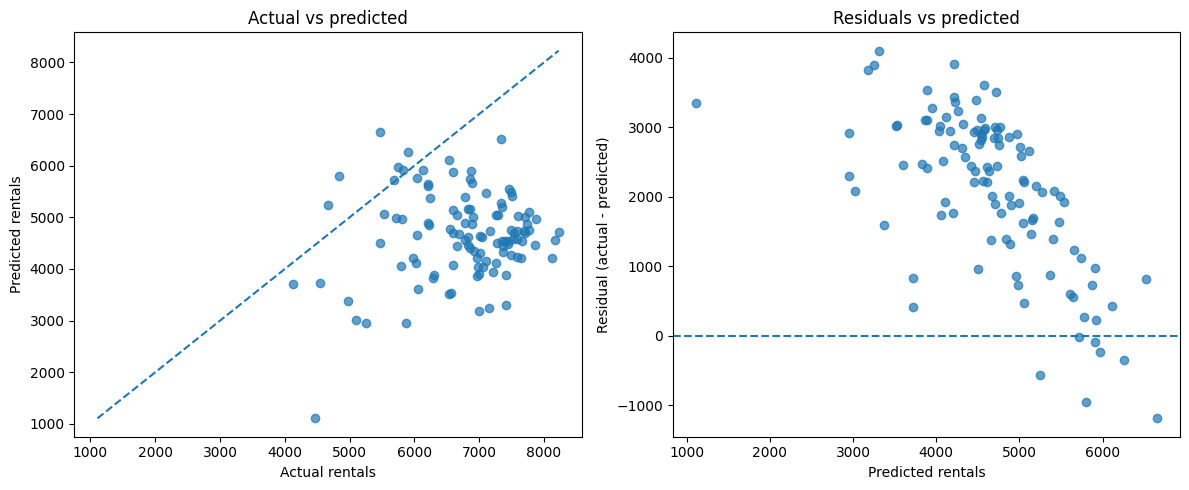

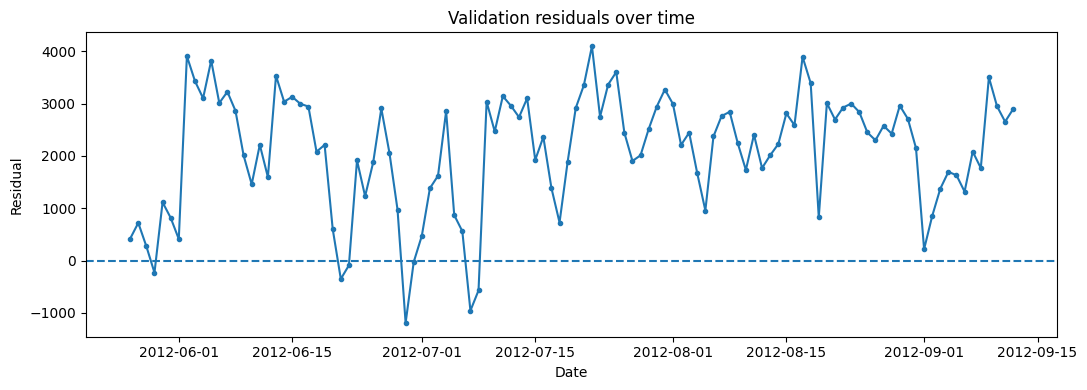

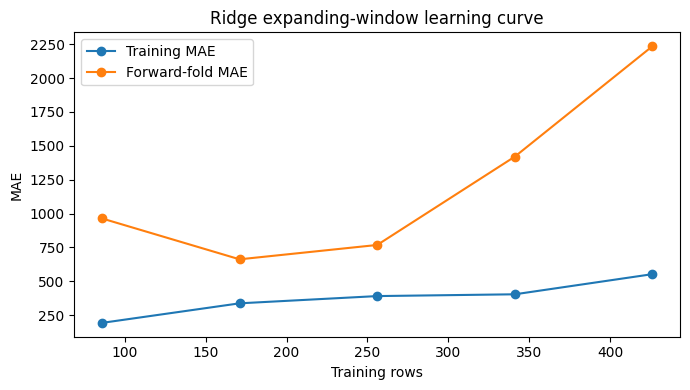

VALIDATION DIAGNOSTIC TESTS
{
  "validation_MAE": 2155.725975469689,
  "validation_RMSE": 2375.1352320055908,
  "validation_R2": -6.738311632575472,
  "validation_residual_mean": 2093.5488722831255,
  "validation_residual_std": 1126.8827420598093,
  "validation_durbin_watson": 0.1671836676554682,
  "breusch_pagan_LM": 41.63735271400631,
  "breusch_pagan_LM_pvalue": 1.0987386637279964e-10,
  "breusch_pagan_F": 65.77910996191052,
  "breusch_pagan_F_pvalue": 8.588769429536929e-13,
  "training_influence_status": "computed_reduced_full_rank_design",
  "training_influence_design_rank": 25,
  "training_influence_design_columns": 25,
  "training_cook_screen_threshold": 0.007827788649706457,
  "training_rows_above_cook_screen": 18,
  "training_max_cooks_distance": 0.12225374248852171
}

VALIDATION ERROR SLICES
   slice_variable          slice  n  mean_actual      MAE
           season              2 26     6779.769 2121.820
           season              3 84     6747.667 2166.221
       weathe

In [39]:

# DS-A3 Step 4: primary feature-plan diagnostics (Ridge WITHOUT yr)
# These results describe the no-year baseline only. The separate Ridge_with_year
# sensitivity candidate is diagnosed in the final review cell below.

import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import TimeSeriesSplit
from sklearn.linear_model import Ridge

import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson

DIAG_DIR = RESULTS_DIR / "diagnostics"
DIAG_DIR.mkdir(parents=True, exist_ok=True)

# Reconstruct the frozen split to avoid accidental row misalignment.
df = df.sort_values("dteday").reset_index(drop=True)
n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

train = df.iloc[:train_end].copy()
val = df.iloc[train_end:val_end].copy()

features = [
    "temp", "atemp", "hum", "windspeed",
    "season", "mnth", "holiday", "weekday",
    "workingday", "weathersit"
]

X_train = train[features]
y_train = train["cnt"]
X_val = val[features]
y_val = val["cnt"]

# Reuse the fitted models from Step 3.
if "Ridge" not in fitted_models:
    raise RuntimeError("Run Step 3 first to fit the models.")

selected_model_name = "Ridge"  # primary feature-plan baseline; excludes yr
selected_model = fitted_models[selected_model_name]

pred = selected_model.predict(X_val)
resid = y_val.to_numpy() - pred

diagnostics = pd.DataFrame({
    "dteday": val["dteday"].to_numpy(),
    "actual_cnt": y_val.to_numpy(),
    "predicted_cnt": pred,
    "residual": resid,
    "absolute_error": np.abs(resid),
    "squared_error": resid ** 2,
})

diagnostics.to_csv(
    DIAG_DIR / "validation_residuals.csv", index=False
)

# 1. Actual versus predicted and residual plots.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(y_val, pred, alpha=0.7)
lo = min(float(y_val.min()), float(pred.min()))
hi = max(float(y_val.max()), float(pred.max()))
axes[0].plot([lo, hi], [lo, hi], linestyle="--")
axes[0].set(
    xlabel="Actual rentals",
    ylabel="Predicted rentals",
    title="Actual vs predicted"
)

axes[1].scatter(pred, resid, alpha=0.7)
axes[1].axhline(0, linestyle="--")
axes[1].set(
    xlabel="Predicted rentals",
    ylabel="Residual (actual - predicted)",
    title="Residuals vs predicted"
)

fig.tight_layout()
fig.savefig(DIAG_DIR / "validation_residual_plots.png", dpi=160)
plt.show()
plt.close(fig)

# 2. Residuals over time.
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(diagnostics["dteday"], diagnostics["residual"], marker=".")
ax.axhline(0, linestyle="--")
ax.set(
    xlabel="Date",
    ylabel="Residual",
    title="Validation residuals over time"
)
fig.tight_layout()
fig.savefig(DIAG_DIR / "validation_residuals_over_time.png", dpi=160)
plt.show()
plt.close(fig)

# 3. Diagnostic tests.
# Breusch-Pagan here is an auxiliary diagnostic using predicted value.
# It tests a limited form of variance association, not every possible
# form of heteroscedasticity.
bp_exog = sm.add_constant(np.asarray(pred))
bp_lm, bp_lm_p, bp_f, bp_f_p = het_breuschpagan(resid, bp_exog)

diagnostic_tests = {
    "validation_MAE": float(mean_absolute_error(y_val, pred)),
    "validation_RMSE": float(np.sqrt(mean_squared_error(y_val, pred))),
    "validation_R2": float(
        1 - np.sum(resid ** 2) /
        np.sum((y_val.to_numpy() - y_val.mean()) ** 2)
    ),
    "validation_residual_mean": float(np.mean(resid)),
    "validation_residual_std": float(np.std(resid, ddof=1)),
    "validation_durbin_watson": float(durbin_watson(resid)),
    "breusch_pagan_LM": float(bp_lm),
    "breusch_pagan_LM_pvalue": float(bp_lm_p),
    "breusch_pagan_F": float(bp_f),
    "breusch_pagan_F_pvalue": float(bp_f_p),
}

# 4. Influence diagnostics on training data using a reduced, rank-checked design.
# Season and workingday are omitted here because they can be redundant with
# month/weekday indicators in this diagnostic encoding. This is an influence
# screen for a reduced OLS design, not the fitted Ridge model.
num_diag = ["temp", "atemp", "hum", "windspeed"]
cat_diag = ["mnth", "holiday", "weekday", "weathersit"]
X_diag = pd.get_dummies(
    train[num_diag + cat_diag], columns=cat_diag, drop_first=True, dtype=float
)
X_ols = sm.add_constant(X_diag, has_constant="add")
rank = int(np.linalg.matrix_rank(X_ols.to_numpy()))
if rank != X_ols.shape[1]:
    diagnostic_tests["training_influence_status"] = "skipped_rank_deficient_design"
    diagnostic_tests["training_influence_design_rank"] = rank
    diagnostic_tests["training_influence_design_columns"] = int(X_ols.shape[1])
    print("Influence diagnostic skipped: reduced design is not full column rank.")
else:
    ols_fit = sm.OLS(y_train.to_numpy(), X_ols).fit()
    influence = ols_fit.get_influence()
    cooks_d = influence.cooks_distance[0]
    leverage = influence.hat_matrix_diag
    influence_table = pd.DataFrame({
        "dteday": train["dteday"].to_numpy(),
        "actual_cnt": y_train.to_numpy(),
        "cooks_distance": cooks_d,
        "leverage": leverage
    })
    cook_threshold = 4 / len(train)
    influence_table["above_cook_screen"] = influence_table["cooks_distance"] > cook_threshold
    influence_table.sort_values("cooks_distance", ascending=False).to_csv(
        DIAG_DIR / "training_influence_reduced_full_rank.csv", index=False
    )
    diagnostic_tests["training_influence_status"] = "computed_reduced_full_rank_design"
    diagnostic_tests["training_influence_design_rank"] = rank
    diagnostic_tests["training_influence_design_columns"] = int(X_ols.shape[1])
    diagnostic_tests["training_cook_screen_threshold"] = float(cook_threshold)
    diagnostic_tests["training_rows_above_cook_screen"] = int((cooks_d > cook_threshold).sum())
    diagnostic_tests["training_max_cooks_distance"] = float(cooks_d.max())

# 5. Critical error slices on validation data.
# These are descriptive subgroup summaries, not causal effects.
slice_df = val[
    ["dteday", "cnt", "season", "weathersit", "temp"]
].copy()
slice_df["prediction"] = pred
slice_df["absolute_error"] = np.abs(y_val.to_numpy() - pred)

slice_df["temperature_group"] = pd.qcut(
    slice_df["temp"],
    q=4,
    duplicates="drop"
).astype(str)

slice_tables = []
for column in ["season", "weathersit", "temperature_group"]:
    grouped = slice_df.groupby(column, observed=True).agg(
        n=("cnt", "size"),
        mean_actual=("cnt", "mean"),
        MAE=("absolute_error", "mean")
    ).reset_index()
    grouped = grouped.rename(columns={column: "slice"})
    grouped.insert(0, "slice_variable", column)
    slice_tables.append(grouped)

slice_results = pd.concat(slice_tables, ignore_index=True)
slice_results.to_csv(
    DIAG_DIR / "validation_error_slices.csv", index=False
)

# 6. Expanding-window learning curve within the training period.
# The future fold is never used to fit that fold's model.
learning_rows = []
ridge_alpha = float(
    selected_model.named_steps["model"].alpha
)

for fold, (fit_idx, eval_idx) in enumerate(
    TimeSeriesSplit(n_splits=5).split(X_train), start=1
):
    fold_model = clone(selected_model)
    fold_model.fit(
        X_train.iloc[fit_idx], y_train.iloc[fit_idx]
    )

    fit_pred = fold_model.predict(X_train.iloc[fit_idx])
    eval_pred = fold_model.predict(X_train.iloc[eval_idx])

    learning_rows.append({
        "fold": fold,
        "training_rows": len(fit_idx),
        "evaluation_rows": len(eval_idx),
        "training_MAE": float(mean_absolute_error(
            y_train.iloc[fit_idx], fit_pred
        )),
        "forward_fold_MAE": float(mean_absolute_error(
            y_train.iloc[eval_idx], eval_pred
        ))
    })

learning_df = pd.DataFrame(learning_rows)
learning_df.to_csv(
    DIAG_DIR / "ridge_learning_curve.csv", index=False
)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(
    learning_df["training_rows"],
    learning_df["training_MAE"],
    marker="o", label="Training MAE"
)
ax.plot(
    learning_df["training_rows"],
    learning_df["forward_fold_MAE"],
    marker="o", label="Forward-fold MAE"
)
ax.set(
    xlabel="Training rows",
    ylabel="MAE",
    title="Ridge expanding-window learning curve"
)
ax.legend()
fig.tight_layout()
fig.savefig(DIAG_DIR / "ridge_learning_curve.png", dpi=160)
plt.show()
plt.close(fig)

with open(DIAG_DIR / "diagnostic_summary.json", "w") as f:
    json.dump(diagnostic_tests, f, indent=2)

print("VALIDATION DIAGNOSTIC TESTS")
print(json.dumps(diagnostic_tests, indent=2))

print("\nVALIDATION ERROR SLICES")
print(slice_results.round(3).to_string(index=False))

print("\nRIDGE LEARNING CURVE")
print(learning_df.round(3).to_string(index=False))

print("\nSaved diagnostics to:", DIAG_DIR)
print("Test set remains untouched.")


In [40]:

# DS-A3: temporal distribution-shift audit
# Uses training and validation data only.

import numpy as np
import pandas as pd

train_summary = {
    "period": "train",
    "rows": len(train),
    "mean_cnt": float(train["cnt"].mean()),
    "median_cnt": float(train["cnt"].median()),
    "std_cnt": float(train["cnt"].std()),
    "min_cnt": int(train["cnt"].min()),
    "max_cnt": int(train["cnt"].max()),
}

val_pred = fitted_models["Ridge"].predict(val[features])
val_residual = val["cnt"].to_numpy() - val_pred

val_summary = {
    "period": "validation",
    "rows": len(val),
    "mean_cnt": float(val["cnt"].mean()),
    "median_cnt": float(val["cnt"].median()),
    "std_cnt": float(val["cnt"].std()),
    "min_cnt": int(val["cnt"].min()),
    "max_cnt": int(val["cnt"].max()),
    "mean_prediction": float(np.mean(val_pred)),
    "mean_residual_actual_minus_predicted": float(
        np.mean(val_residual)
    ),
}

print("PERIOD SUMMARY")
print(pd.DataFrame([train_summary, val_summary]).round(3).to_string(index=False))

monthly = pd.DataFrame({
    "date": val["dteday"].to_numpy(),
    "actual_cnt": val["cnt"].to_numpy(),
    "predicted_cnt": val_pred,
    "residual": val_residual,
})

monthly["month"] = pd.to_datetime(monthly["date"]).dt.to_period("M").astype(str)

monthly_summary = monthly.groupby("month").agg(
    rows=("actual_cnt", "size"),
    mean_actual=("actual_cnt", "mean"),
    mean_predicted=("predicted_cnt", "mean"),
    mean_residual=("residual", "mean"),
    MAE=("residual", lambda x: np.abs(x).mean())
).reset_index()

monthly_summary.to_csv(
    DIAG_DIR / "validation_monthly_error.csv",
    index=False
)

print("\nMONTHLY VALIDATION PERFORMANCE")
print(monthly_summary.round(2).to_string(index=False))


PERIOD SUMMARY
    period  rows  mean_cnt  median_cnt  std_cnt  min_cnt  max_cnt  mean_prediction  mean_residual_actual_minus_predicted
     train   511  3794.211      3974.0 1586.303      431     8362              NaN                                   NaN
validation   110  6755.255      6897.5  857.726     4127     8227         4661.706                              2093.549

MONTHLY VALIDATION PERFORMANCE
  month  rows  mean_actual  mean_predicted  mean_residual     MAE
2012-05     6      6517.67         5999.01         518.66  595.80
2012-06    30      6761.00         4730.92        2030.08 2140.76
2012-07    31      6567.97         4402.12        2165.84 2264.44
2012-08    31      6919.45         4461.74        2457.71 2457.71
2012-09    12      6919.33         5007.19        1912.15 1912.15


In [41]:

import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Same frozen chronological train/validation split.
numeric_cols = ["temp", "atemp", "hum", "windspeed"]
categorical_cols = [
    "season", "mnth", "holiday", "weekday",
    "workingday", "weathersit"
]

feature_sets = {
    "Ridge_without_yr": numeric_cols + categorical_cols,
    "Ridge_with_yr": numeric_cols + categorical_cols + ["yr"]
}

alpha_grid = [0.01, 0.1, 1, 10, 100, 1000]
cv = TimeSeriesSplit(n_splits=5)

results = []
validation_predictions = pd.DataFrame({
    "date": pd.to_datetime(val["dteday"]).dt.strftime("%Y-%m-%d"),
    "actual_cnt": val["cnt"].to_numpy()
})

for model_name, feature_cols in feature_sets.items():
    categorical = categorical_cols.copy()
    if "yr" in feature_cols:
        categorical.append("yr")

    preprocessor = ColumnTransformer([
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numeric_cols),
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical)
    ])

    best_alpha = None
    best_cv_mae = float("inf")

    # Select alpha using training data only.
    for alpha in alpha_grid:
        pipeline = Pipeline([
            ("preprocessor", preprocessor),
            ("model", Ridge(alpha=alpha))
        ])

        scores = cross_val_score(
            pipeline,
            train[feature_cols],
            train["cnt"],
            cv=cv,
            scoring="neg_mean_absolute_error"
        )
        cv_mae = -scores.mean()

        if cv_mae < best_cv_mae:
            best_cv_mae = cv_mae
            best_alpha = alpha

    # Fit on all training data and evaluate on validation.
    final_model = Pipeline([
        ("preprocessor", preprocessor),
        ("model", Ridge(alpha=best_alpha))
    ])
    final_model.fit(train[feature_cols], train["cnt"])

    predictions = final_model.predict(val[feature_cols])
    residuals = val["cnt"].to_numpy() - predictions

    results.append({
        "model": model_name,
        "selected_alpha": best_alpha,
        "training_cv_MAE": best_cv_mae,
        "validation_MAE": mean_absolute_error(
            val["cnt"], predictions
        ),
        "validation_RMSE": np.sqrt(
            mean_squared_error(val["cnt"], predictions)
        ),
        "validation_R2": r2_score(val["cnt"], predictions),
        "validation_mean_residual": residuals.mean()
    })

    validation_predictions[model_name + "_prediction"] = predictions

comparison = pd.DataFrame(results)
display(comparison.round(3))

output_dir = Path(
    "/content/DS-A3-Regression-Baseline/results"
)
output_dir.mkdir(parents=True, exist_ok=True)

comparison.to_csv(
    output_dir / "year_indicator_comparison.csv", index=False
)
validation_predictions.to_csv(
    output_dir / "year_indicator_predictions.csv", index=False
)

print("Saved comparison and predictions to:", output_dir)
print("The test set has not been used.")


,model,selected_alpha,training_cv_MAE,validation_MAE,validation_RMSE,validation_R2,validation_mean_residual
0,Ridge_without_yr,0.01,1209.907,2155.726,2375.135,-6.738,2093.549
1,Ridge_with_yr,0.01,949.073,786.386,963.466,-0.273,204.902


Saved comparison and predictions to: /content/DS-A3-Regression-Baseline/results
The test set has not been used.


In [42]:

import pandas as pd
from pathlib import Path
from sklearn.metrics import mean_absolute_error
import numpy as np

output_dir = Path(
    "/content/DS-A3-Regression-Baseline/results"
)

pred_path = output_dir / "year_indicator_predictions.csv"
pred = pd.read_csv(pred_path)
pred["date"] = pd.to_datetime(pred["date"])
pred["month"] = pred["date"].dt.to_period("M").astype(str)

rows = []

for month, group in pred.groupby("month", sort=True):
    actual = group["actual_cnt"]

    for model_name, col in [
        ("Ridge_without_yr", "Ridge_without_yr_prediction"),
        ("Ridge_with_yr", "Ridge_with_yr_prediction")
    ]:
        residual = actual - group[col]
        rows.append({
            "month": month,
            "model": model_name,
            "n_days": len(group),
            "mean_actual": actual.mean(),
            "mean_predicted": group[col].mean(),
            "mean_residual": residual.mean(),
            "MAE": mean_absolute_error(actual, group[col])
        })

monthly = pd.DataFrame(rows)
display(monthly.round(2))

monthly.to_csv(
    output_dir / "year_indicator_monthly_comparison.csv",
    index=False
)
print("Monthly comparison saved.")


,month,model,n_days,mean_actual,mean_predicted,mean_residual,MAE
0,2012-05,Ridge_without_yr,6,6517.67,5999.01,518.66,595.80
1,2012-05,Ridge_with_yr,6,6517.67,6817.53,-299.86,447.92
2,2012-06,Ridge_without_yr,30,6761.00,4730.92,2030.08,2140.76
3,2012-06,Ridge_with_yr,30,6761.00,6729.65,31.35,961.86
4,2012-07,Ridge_without_yr,31,6567.97,4402.12,2165.84,2264.44
5,2012-07,Ridge_with_yr,31,6567.97,6389.42,178.55,845.29
6,2012-08,Ridge_without_yr,31,6919.45,4461.74,2457.71,2457.71
7,2012-08,Ridge_with_yr,31,6919.45,6409.86,509.59,669.48
8,2012-09,Ridge_without_yr,12,6919.33,5007.19,1912.15,1912.15
9,2012-09,Ridge_with_yr,12,6919.33,6747.22,172.11,666.77


Monthly comparison saved.


In [43]:

import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

output_dir = Path(
    "/content/DS-A3-Regression-Baseline/results"
)

# Use training data only to construct the historical baseline.
train_dates = train[["dteday", "cnt"]].copy()
train_dates["date"] = pd.to_datetime(train_dates["dteday"])
train_dates["month_day"] = train_dates["date"].dt.strftime("%m-%d")

# Keep only 2011 observations as historical same-date references.
history_2011 = train_dates[
    train_dates["date"].dt.year == 2011
][["month_day", "cnt"]].rename(
    columns={"cnt": "seasonal_naive_prediction"}
)

# Match each validation date to the same month/day in 2011.
seasonal = val[["dteday", "cnt"]].copy()
seasonal["date"] = pd.to_datetime(seasonal["dteday"])
seasonal["month_day"] = seasonal["date"].dt.strftime("%m-%d")

seasonal = seasonal.merge(
    history_2011, on="month_day", how="left", validate="many_to_one"
)

assert seasonal["seasonal_naive_prediction"].notna().all(), (
    "Some validation dates have no matching 2011 historical observation."
)

# Load saved predictions from the two Ridge candidates.
pred = pd.read_csv(output_dir / "year_indicator_predictions.csv")
pred["date"] = pd.to_datetime(pred["date"])
seasonal["date"] = pd.to_datetime(seasonal["date"])

comparison_data = seasonal.merge(
    pred[[
        "date", "Ridge_without_yr_prediction", "Ridge_with_yr_prediction"
    ]],
    on="date",
    how="left",
    validate="one_to_one"
)

actual = comparison_data["cnt"]
model_columns = {
    "Seasonal_naive_2011": "seasonal_naive_prediction",
    "Ridge_without_yr": "Ridge_without_yr_prediction",
    "Ridge_with_yr": "Ridge_with_yr_prediction"
}

results = []
for name, column in model_columns.items():
    prediction = comparison_data[column]
    results.append({
        "model": name,
        "MAE": mean_absolute_error(actual, prediction),
        "RMSE": np.sqrt(mean_squared_error(actual, prediction)),
        "R2": r2_score(actual, prediction),
        "mean_residual_actual_minus_predicted":
            (actual - prediction).mean()
    })

comparison = pd.DataFrame(results).sort_values("MAE")
display(comparison.round(3))

comparison_data["month"] = comparison_data["date"].dt.to_period("M").astype(str)
comparison_data.to_csv(
    output_dir / "seasonal_naive_validation_predictions.csv",
    index=False
)
comparison.to_csv(
    output_dir / "seasonal_naive_validation_comparison.csv",
    index=False
)

print("Saved seasonal-naive comparison. Test set remains untouched.")


,model,MAE,RMSE,R2,mean_residual_actual_minus_predicted
2,Ridge_with_yr,786.386,963.466,-0.273,204.902
1,Ridge_without_yr,2155.726,2375.135,-6.738,2093.549
0,Seasonal_naive_2011,2243.445,2517.637,-7.695,2243.082


Saved seasonal-naive comparison. Test set remains untouched.


In [44]:

import pandas as pd
from pathlib import Path

output_dir = Path("/content/DS-A3-Regression-Baseline/results")

# 1. Verify the frozen chronological split.
assert train["dteday"].is_monotonic_increasing
assert val["dteday"].is_monotonic_increasing
assert train["dteday"].max() < val["dteday"].min()

print("Training dates:", train["dteday"].min(), "to", train["dteday"].max())
print("Validation dates:", val["dteday"].min(), "to", val["dteday"].max())

# 2. Check that known target/leakage variables are excluded.
forbidden = {"cnt", "casual", "registered", "instant", "dteday"}
candidate_features = [
    "temp", "atemp", "hum", "windspeed",
    "season", "mnth", "holiday", "weekday",
    "workingday", "weathersit", "yr"
]

assert not (set(candidate_features) & forbidden)
assert set(candidate_features).issubset(train.columns)

print("\nLeakage-variable exclusion check: PASS")
print("Candidate features:", candidate_features)

# 3. Verify the saved validation predictions correspond to the validation dates.
saved = pd.read_csv(output_dir / "year_indicator_predictions.csv")
saved_dates = pd.to_datetime(saved["date"]).reset_index(drop=True)
expected_dates = pd.to_datetime(val["dteday"]).reset_index(drop=True)

assert len(saved) == len(val)
assert saved_dates.equals(expected_dates)
assert saved["Ridge_with_yr_prediction"].notna().all()

print("Validation prediction alignment: PASS")
print("Number of validation predictions:", len(saved))

# 4. Save a concise audit record.
audit = pd.DataFrame([
    {"check": "Chronological split", "status": "PASS"},
    {"check": "Target/leakage variables excluded", "status": "PASS"},
    {"check": "Validation prediction alignment", "status": "PASS"},
    {"check": "Test set used for model selection", "status": "NO"}
])

audit.to_csv(output_dir / "leakage_audit.csv", index=False)
display(audit)
print("Audit saved to:", output_dir / "leakage_audit.csv")


Training dates: 2011-01-01 00:00:00 to 2012-05-25 00:00:00
Validation dates: 2012-05-26 00:00:00 to 2012-09-12 00:00:00

Leakage-variable exclusion check: PASS
Candidate features: ['temp', 'atemp', 'hum', 'windspeed', 'season', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'yr']
Validation prediction alignment: PASS
Number of validation predictions: 110


,check,status
0,Chronological split,PASS
1,Target/leakage variables excluded,PASS
2,Validation prediction alignment,PASS
3,Test set used for model selection,NO


Audit saved to: /content/DS-A3-Regression-Baseline/results/leakage_audit.csv


In [45]:

import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.metrics import mean_absolute_error

output_dir = Path("/content/DS-A3-Regression-Baseline/results")
pred = pd.read_csv(output_dir / "year_indicator_predictions.csv")

pred["date"] = pd.to_datetime(pred["date"])
pred["residual"] = pred["actual_cnt"] - pred["Ridge_with_yr_prediction"]
pred["absolute_error"] = pred["residual"].abs()
pred["percentage_error"] = (
    pred["absolute_error"] / pred["actual_cnt"].replace(0, np.nan)
) * 100

# Largest absolute errors.
print("TOP 10 VALIDATION ERRORS")
display(
    pred.sort_values("absolute_error", ascending=False)[[
        "date", "actual_cnt", "Ridge_with_yr_prediction",
        "residual", "absolute_error", "percentage_error"
    ]].head(10).round(2)
)

# Error distribution summaries.
print("\nERROR SUMMARY")
print("Mean residual (actual - predicted):", round(pred["residual"].mean(), 2))
print("Median absolute error:", round(pred["absolute_error"].median(), 2))
print("90th percentile absolute error:", round(pred["absolute_error"].quantile(0.90), 2))
print("Maximum absolute error:", round(pred["absolute_error"].max(), 2))
print("Mean absolute percentage error (%):", round(pred["percentage_error"].mean(), 2))

# Save detailed validation error analysis.
pred.to_csv(
    output_dir / "ridge_with_year_validation_errors.csv",
    index=False
)
print("\nSaved validation error analysis.")
print("Test set remains untouched.")


TOP 10 VALIDATION ERRORS


,date,actual_cnt,Ridge_with_yr_prediction,residual,absolute_error,percentage_error
34,2012-06-29,5463,8135.90,-2672.90,2672.90,48.93
42,2012-07-07,4840,7363.09,-2523.09,2523.09,52.13
43,2012-07-08,4672,6924.09,-2252.09,2252.09,48.20
26,2012-06-21,5905,7908.81,-2003.81,2003.81,33.93
57,2012-07-22,7410,5532.91,1877.09,1877.09,25.33
35,2012-06-30,5687,7552.41,-1865.41,1865.41,32.80
27,2012-06-22,5823,7670.42,-1847.42,1847.42,31.73
6,2012-06-01,4127,5903.61,-1776.61,1776.61,43.05
7,2012-06-02,8120,6412.21,1707.79,1707.79,21.03
106,2012-09-09,8227,6528.93,1698.07,1698.07,20.64



ERROR SUMMARY
Mean residual (actual - predicted): 204.9
Median absolute error: 774.11
90th percentile absolute error: 1481.86
Maximum absolute error: 2672.9
Mean absolute percentage error (%): 12.09

Saved validation error analysis.
Test set remains untouched.


In [46]:

import pandas as pd
import numpy as np
from pathlib import Path

output_dir = Path("/content/DS-A3-Regression-Baseline/results")

pred = pd.read_csv(
    output_dir / "year_indicator_predictions.csv",
    parse_dates=["date"]
)

# Join predictions to the corresponding validation features.
val_features = val.copy()
val_features["date"] = pd.to_datetime(val_features["dteday"])

analysis = val_features.merge(
    pred[["date", "actual_cnt", "Ridge_with_yr_prediction"]],
    on="date",
    how="inner",
    validate="one_to_one"
)

assert len(analysis) == len(val), "Validation rows were lost or duplicated."

analysis["residual"] = (
    analysis["actual_cnt"] - analysis["Ridge_with_yr_prediction"]
)
analysis["absolute_error"] = analysis["residual"].abs()

# Grouped performance summaries.
def summarize_slice(data, group_col):
    result = (
        data.groupby(group_col, observed=True)
        .agg(
            n=("actual_cnt", "size"),
            mean_actual=("actual_cnt", "mean"),
            mean_predicted=("Ridge_with_yr_prediction", "mean"),
            mean_residual=("residual", "mean"),
            MAE=("absolute_error", "mean")
        )
        .reset_index()
    )
    return result.round(2)

for col in ["season", "weathersit"]:
    print(f"\nPERFORMANCE BY {col.upper()}")
    display(summarize_slice(analysis, col))

# Temperature quartiles are defined using validation temperature values
# for descriptive error analysis only, not for model fitting or tuning.
analysis["temperature_group"] = pd.qcut(
    analysis["temp"], q=4, duplicates="drop"
)
print("\nPERFORMANCE BY TEMPERATURE GROUP")
display(summarize_slice(analysis, "temperature_group"))

analysis.to_csv(
    output_dir / "ridge_with_year_validation_slice_analysis.csv",
    index=False
)
print("\nSaved slice analysis. Test set remains untouched.")



PERFORMANCE BY SEASON


,season,n,mean_actual,mean_predicted,mean_residual,MAE
0,2,26,6779.77,6476.81,302.96,799.12
1,3,84,6747.67,6573.12,174.55,782.44



PERFORMANCE BY WEATHERSIT


,weathersit,n,mean_actual,mean_predicted,mean_residual,MAE
0,1,82,6928.24,6750.47,177.78,794.41
1,2,27,6314.93,6049.59,265.34,761.61
2,3,1,4459.00,3661.59,797.41,797.41



PERFORMANCE BY TEMPERATURE GROUP


,temperature_group,n,mean_actual,mean_predicted,mean_residual,MAE
0,"(0.54, 0.663]",28,6745.93,6127.50,618.43,915.36
1,"(0.663, 0.716]",29,6926.41,6511.62,414.79,632.30
2,"(0.716, 0.752]",25,7022.92,6599.39,423.53,659.56
3,"(0.752, 0.862]",28,6348.32,6969.54,-621.21,930.24



Saved slice analysis. Test set remains untouched.


In [47]:

import sys
import json
import platform
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn
import statsmodels

output_dir = Path("/content/DS-A3-Regression-Baseline/results")
output_dir.mkdir(parents=True, exist_ok=True)

# Record runtime and key package versions.
environment = {
    "python_version": sys.version,
    "platform": platform.platform(),
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__,
    "scikit_learn_version": sklearn.__version__,
    "statsmodels_version": statsmodels.__version__,
    "random_seed": 20261021,
    "dataset": "UCI Bike Sharing day.csv",
    "dataset_sha256": (
        "a6bcf826782d3c0fbfdcbeead17cd0884185a0dafe8ff10cd48a874ee7ba18be"
    ),
    "split": {
        "method": "chronological",
        "training_rows": int(len(train)),
        "validation_rows": int(len(val)),
        "test_rows": 110,
        "test_used_for_model_selection": False
    }
}

with open(output_dir / "environment_record.json", "w") as f:
    json.dump(environment, f, indent=2)

# Save a human-readable package lock for the libraries used.
packages = [
    f"numpy=={np.__version__}",
    f"pandas=={pd.__version__}",
    f"scikit-learn=={sklearn.__version__}",
    f"statsmodels=={statsmodels.__version__}",
    f"matplotlib=={__import__('matplotlib').__version__}"
]

with open(output_dir / "requirements-lock.txt", "w") as f:
    f.write("\n".join(packages) + "\n")

print(json.dumps(environment, indent=2))
print("\nSaved:")
print(output_dir / "environment_record.json")
print(output_dir / "requirements-lock.txt")


{
  "python_version": "3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]",
  "platform": "Linux-6.6.122+-x86_64-with-glibc2.39",
  "numpy_version": "2.1.3",
  "pandas_version": "2.2.3",
  "scikit_learn_version": "1.6.1",
  "statsmodels_version": "0.15.0",
  "random_seed": 20261021,
  "dataset": "UCI Bike Sharing day.csv",
  "dataset_sha256": "a6bcf826782d3c0fbfdcbeead17cd0884185a0dafe8ff10cd48a874ee7ba18be",
  "split": {
    "method": "chronological",
    "training_rows": 511,
    "validation_rows": 110,
    "test_rows": 110,
    "test_used_for_model_selection": false
  }
}

Saved:
/content/DS-A3-Regression-Baseline/results/environment_record.json
/content/DS-A3-Regression-Baseline/results/requirements-lock.txt


## Selected sensitivity candidate: Ridge with `yr`

The next cell diagnoses the saved validation predictions for `Ridge_with_year`, the best candidate among the reproduced model variants by validation MAE. It is a sensitivity-analysis candidate; the primary feature plan still excludes `yr`. This cell uses validation predictions only and does not read or score the test partition.


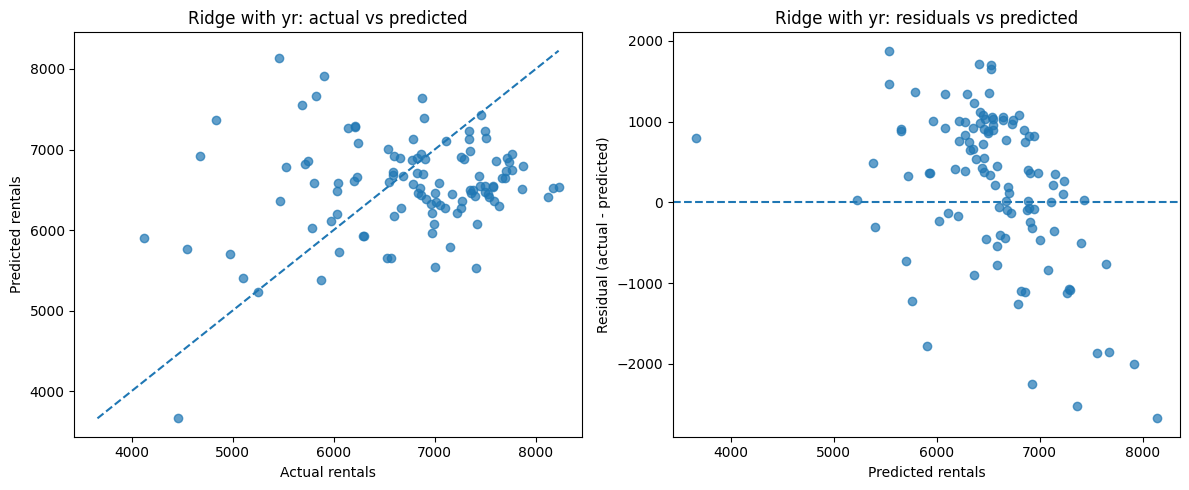

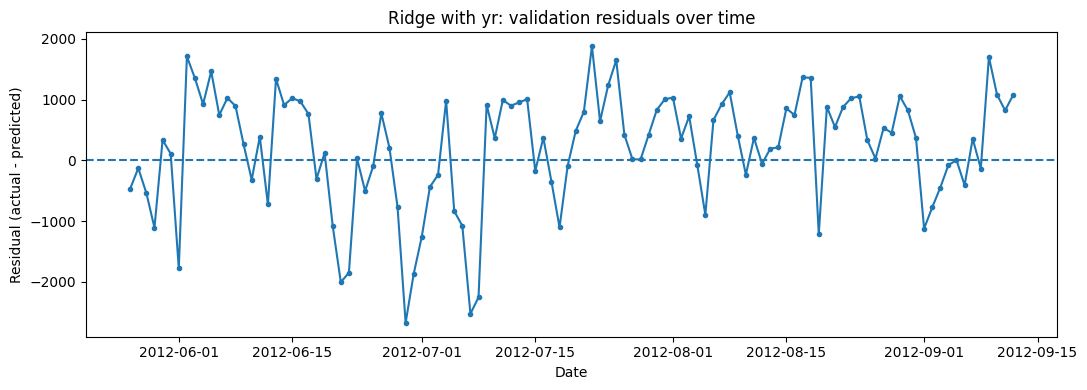

{
  "model": "Ridge_with_year",
  "validation_rows": 110,
  "validation_date_start": "2012-05-26",
  "validation_date_end": "2012-09-12",
  "MAE": 786.3861913311049,
  "RMSE": 963.4656295205131,
  "R2": -0.2733329699671694,
  "mean_residual_actual_minus_predicted": 204.90207552941385,
  "residual_sd": 945.7336720852154,
  "durbin_watson": 0.9387183454599337,
  "breusch_pagan_LM_pvalue_using_prediction_only": 0.02175320704646279,
  "breusch_pagan_F_pvalue_using_prediction_only": 0.021656917270883407,
  "interpretation_note": "Exploratory diagnostics; low Durbin-Watson may indicate serial correlation and the prediction-only Breusch-Pagan test is limited. Negative R2 means this candidate is not yet a reliable forecasting solution.",
  "test_set_used": false
}

Validation slice counts (interpret small groups cautiously):
slice_variable slice_value  n  mean_actual  mean_predicted        MAE
        season           2 26  6779.769231     6476.811466 799.124648
        season           3 84  

In [48]:
# DS-A3 review correction: diagnostics aligned to Ridge_with_year validation predictions
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan

PROJECT = Path("/content/DS-A3-Regression-Baseline")
RESULTS = PROJECT / "results"
DIAG_DIR = RESULTS / "diagnostics"
DIAG_DIR.mkdir(parents=True, exist_ok=True)
pred_path = RESULTS / "year_indicator_predictions.csv"
if not pred_path.is_file():
    raise FileNotFoundError(
        f"Missing {pred_path}. Run the year-indicator comparison cell first; "
        "do not substitute test predictions."
    )
pred = pd.read_csv(pred_path, parse_dates=["date"])
pred = pred.rename(columns={
    "date": "dteday",
    "Ridge_with_yr_prediction": "pred_Ridge_with_year",
})
required_cols = {"dteday", "actual_cnt", "pred_Ridge_with_year"}
missing = required_cols - set(pred.columns)
if missing:
    raise ValueError(f"Prediction file missing columns: {sorted(missing)}")
if pred["dteday"].duplicated().any() or pred[list(required_cols)].isna().any().any():
    raise ValueError("Duplicate dates or missing values in validation prediction table.")
pred = pred.sort_values("dteday").reset_index(drop=True)
pred["residual"] = pred["actual_cnt"] - pred["pred_Ridge_with_year"]
pred["absolute_error"] = pred["residual"].abs()
pred.to_csv(DIAG_DIR / "validation_residuals_Ridge_with_year.csv", index=False)

y = pred["actual_cnt"].to_numpy(dtype=float)
yhat = pred["pred_Ridge_with_year"].to_numpy(dtype=float)
r = y - yhat

# Actual vs predicted, residual vs predicted, and residual over time.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
lo = min(float(y.min()), float(yhat.min())); hi = max(float(y.max()), float(yhat.max()))
axes[0].scatter(y, yhat, alpha=0.7); axes[0].plot([lo, hi], [lo, hi], linestyle="--")
axes[0].set(xlabel="Actual rentals", ylabel="Predicted rentals", title="Ridge with yr: actual vs predicted")
axes[1].scatter(yhat, r, alpha=0.7); axes[1].axhline(0, linestyle="--")
axes[1].set(xlabel="Predicted rentals", ylabel="Residual (actual - predicted)", title="Ridge with yr: residuals vs predicted")
fig.tight_layout(); fig.savefig(DIAG_DIR / "validation_residual_plots_Ridge_with_year.png", dpi=160); plt.show(); plt.close(fig)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(pred["dteday"], r, marker="."); ax.axhline(0, linestyle="--")
ax.set(xlabel="Date", ylabel="Residual (actual - predicted)", title="Ridge with yr: validation residuals over time")
fig.tight_layout(); fig.savefig(DIAG_DIR / "validation_residuals_over_time_Ridge_with_year.png", dpi=160); plt.show(); plt.close(fig)

# Exploratory residual diagnostics; interpret cautiously because this is a time-ordered validation segment.
bp = het_breuschpagan(r, sm.add_constant(yhat))
summary = {
    "model": "Ridge_with_year",
    "validation_rows": int(len(pred)),
    "validation_date_start": str(pred["dteday"].min().date()),
    "validation_date_end": str(pred["dteday"].max().date()),
    "MAE": float(mean_absolute_error(y, yhat)),
    "RMSE": float(np.sqrt(mean_squared_error(y, yhat))),
    "R2": float(r2_score(y, yhat)),
    "mean_residual_actual_minus_predicted": float(np.mean(r)),
    "residual_sd": float(np.std(r, ddof=1)),
    "durbin_watson": float(durbin_watson(r)),
    "breusch_pagan_LM_pvalue_using_prediction_only": float(bp[1]),
    "breusch_pagan_F_pvalue_using_prediction_only": float(bp[3]),
    "interpretation_note": "Exploratory diagnostics; low Durbin-Watson may indicate serial correlation and the prediction-only Breusch-Pagan test is limited. Negative R2 means this candidate is not yet a reliable forecasting solution.",
    "test_set_used": False
}
with open(DIAG_DIR / "diagnostic_summary_Ridge_with_year.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)
print(json.dumps(summary, indent=2))

# Error slices use only validation rows and are descriptive, not causal.
# Rejoin source features by date and validate one-to-one alignment.
dataset_path = PROJECT / "data" / "day.csv"
if dataset_path.is_file():
    all_df = pd.read_csv(dataset_path, parse_dates=["dteday"]).sort_values("dteday").reset_index(drop=True)
    val_start, val_end = int(len(all_df) * 0.70), int(len(all_df) * 0.85)
    val_features = all_df.iloc[val_start:val_end].copy()
    merged = val_features.merge(pred, on="dteday", how="inner", validate="one_to_one")
    if len(merged) != len(pred):
        raise ValueError("Prediction dates do not match the chronological validation partition.")
    slice_rows = []
    for col in ["season", "weathersit", "mnth"]:
        for value, group in merged.groupby(col, observed=True):
            slice_rows.append({"slice_variable": col, "slice_value": str(value), "n": int(len(group)), "mean_actual": float(group["actual_cnt"].mean()), "mean_predicted": float(group["pred_Ridge_with_year"].mean()), "MAE": float(group["absolute_error"].mean())})
    slices = pd.DataFrame(slice_rows)
    slices.to_csv(DIAG_DIR / "validation_error_slices_Ridge_with_year.csv", index=False)
    print("\nValidation slice counts (interpret small groups cautiously):")
    print(slices.to_string(index=False))
else:
    print(f"Source data file not found at {dataset_path}; skipped feature-slice summaries.")
print("\nSaved selected-candidate diagnostics to:", DIAG_DIR)
print("Test set remains untouched.")
